# Quantile mapping as a post-step (not built)

**The question:** does mapping the forecasts onto the observed speed distribution improve the
linear model and the hybrid?

**Why it might:** least-squares models shrink towards the mean. On the training years the
forecasts' spread is only about 0.73 (linear) / 0.77 (hybrid) of the observed speeds' spread, so
quiet wind is over-forecast and fast streams under-forecast. Collin et al. (2025) report a 22%
lower peak error after a distribution correction.

**The post-step** (`training.quantile_mapping.QuantileMap`): for each lead, the forecast's quantile
among the training forecasts is replaced by the same quantile of the observed training speeds
(100 knots, 0.5%–99.5%; beyond them the end offsets are added). A blend
f' = f + α (map(f) − f) is scored for α ∈ {0, 0.25, 0.5, 0.75, 1}; α = 0 is the shipped model.

**Setup** (`python -m training.quantile_mapping`):
- Six yearly walk-forward folds (2019-10 → 2025-10). Per fold, the linear model (shipped config,
  data fixes and cap) and the hybrid's trees are refitted on the data before the fold, and the map
  is learned from their in-sample forecasts on those years.
- Score: per-run mean TIMSE / persistence; summary: the geometric mean over folds.
- "Fast runs": runs whose observed speed peaks above 600 km/s, scored against α = 0 on the same runs.
- The eval year is not used.

1. Fold scores
2. Score against spread
3. What the map does (2024 fold)
4. Why the 2019 fold gains
5. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import quantile_mapping as qm

df = pd.read_csv(qm.EXPERIMENTS / "quantile_mapping.csv").set_index("fold")
A = qm.ALPHAS

## 1. Fold scores (lower is better)

In [2]:
def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


rows = {}
for a in A:
    r = {}
    for m in ("linear", "hybrid"):
        r[m] = geo(f"{m} a={a:g}")
        r[f"{m} vs α=0"] = r[m] / geo(f"{m} a=0") - 1
        r[f"{m} folds won"] = int((df[f"{m} a={a:g}"] < df[f"{m} a=0"]).sum())
        r[f"{m} fast runs vs α=0"] = geo(f"{m} a={a:g} fast") - 1
    rows[a] = r
summary = pd.DataFrame(rows).T
summary.index.name = "α"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)
    display(df[[f"{m} a={a:g}" for m in ("linear", "hybrid") for a in A]].T)
print("fast runs per fold:", df["fast runs"].astype(int).to_dict())

,linear,linear vs α=0,linear folds won,linear fast runs vs α=0,hybrid,hybrid vs α=0,hybrid folds won,hybrid fast runs vs α=0
α,,,,,,,,
0.0000,0.4375,0.0000,0.0000,0.0000,0.4253,0.0000,0.0000,0.0000
0.2500,0.4416,0.0092,1.0000,0.1233,0.4303,0.0118,1.0000,0.1109
0.5000,0.4767,0.0896,1.0000,0.2672,0.4595,0.0803,0.0000,0.2383
0.7500,0.5439,0.2430,0.0000,0.4314,0.5122,0.2043,0.0000,0.3818
1.0000,0.6406,0.4642,0.0000,0.6157,0.5868,0.3796,0.0000,0.5413


fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear a=0,0.4282,0.3678,0.4981,0.4626,0.5554,0.3481
linear a=0.25,0.3733,0.3733,0.5256,0.4952,0.5718,0.3574
linear a=0.5,0.3919,0.4102,0.5688,0.5524,0.6164,0.3772
linear a=0.75,0.4840,0.4783,0.6275,0.6343,0.6892,0.4075
linear a=1,0.6496,0.5777,0.7020,0.7409,0.7902,0.4483
hybrid a=0,0.3960,0.3604,0.4900,0.4573,0.5488,0.3371
hybrid a=0.25,0.3749,0.3661,0.5164,0.4785,0.5528,0.3387
hybrid a=0.5,0.4097,0.3962,0.5553,0.5182,0.5785,0.3481
hybrid a=0.75,0.5002,0.4508,0.6066,0.5767,0.6261,0.3655
hybrid a=1,0.6466,0.5298,0.6704,0.6538,0.6955,0.3908


fast runs per fold: {'2019-10': 97, '2020-10': 141, '2021-10': 418, '2022-10': 341, '2023-10': 148, '2024-10': 527}


## 2. Score against spread

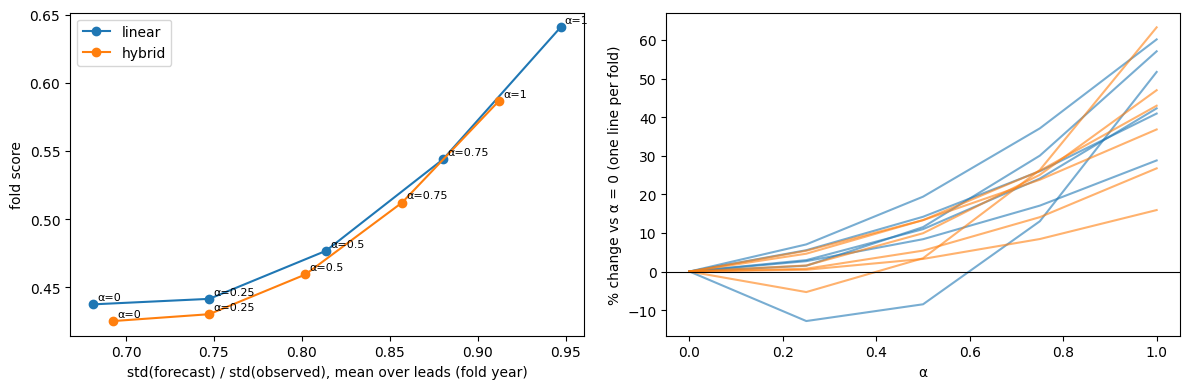

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, c in (("linear", "C0"), ("hybrid", "C1")):
    sp = [df[f"{m} a={a:g} spread"].mean() for a in A]
    axes[0].plot(sp, [geo(f"{m} a={a:g}") for a in A], "o-", color=c, label=m)
    for a, x, y in zip(A, sp, [geo(f"{m} a={a:g}") for a in A], strict=True):
        axes[0].annotate(f"α={a:g}", (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
    for fold in df.index:
        axes[1].plot(A, 100 * (df.loc[fold, [f"{m} a={a:g}" for a in A]].to_numpy()
                               / df.loc[fold, f"{m} a=0"] - 1), "-", color=c, alpha=0.6)
axes[0].set_xlabel("std(forecast) / std(observed), mean over leads (fold year)")
axes[0].set_ylabel("fold score")
axes[0].legend()
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("α")
axes[1].set_ylabel("% change vs α = 0 (one line per fold)")
plt.tight_layout()

## 3. What the map does (2024 fold)

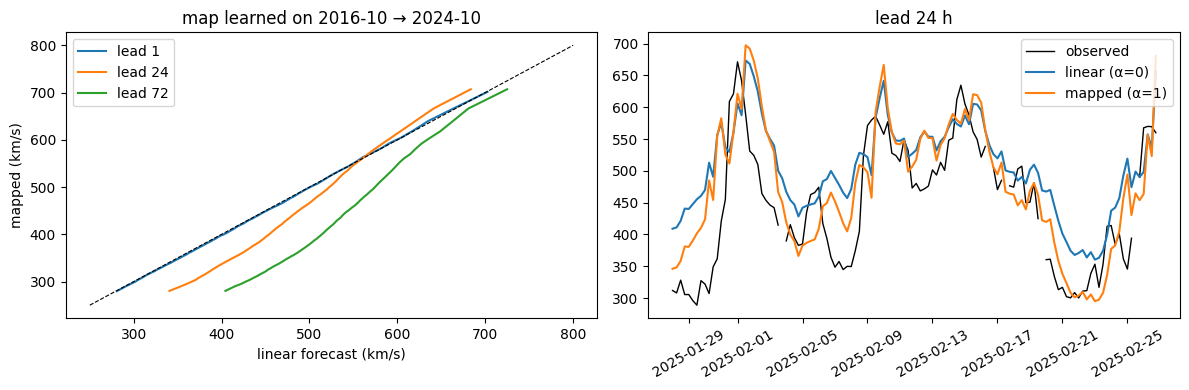

In [4]:
from feature_engineering.recurrence import targets
from models.linear_model import LinearModel
from training import compare_history as ch
from training.datasets import DATA_START

data = ch.Data()


def fit_fold(start, end):
    fold = data.fold(start, end)
    start_pos = data.series.index.get_loc(start)
    fit6 = data.runs6[(data.runs6 >= DATA_START) & (data.runs6 < start)]
    pos6 = data.series.index.get_indexer(fit6)
    lin = LinearModel(data.linear_cfg).fit(
        data.values, pos6, data.x(fit6, data.linear_cfg.features), end=start_pos)
    train_f = lin.forecast(data.values, pos6, data.x(fit6, data.linear_cfg.features))
    qmap = qm.QuantileMap(train_f, targets(data.values, pos6, end=start_pos))
    f = lin.forecast(data.values, fold["pos"], data.x(fold["t0s"], data.linear_cfg.features))
    return fold, qmap, f


start, end = qm.YEARLY[-1]
fold, qmap, f = fit_fold(start, end)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k, c in ((0, "C0"), (23, "C1"), (71, "C2")):
    axes[0].plot(qmap.f_knots[k], qmap.y_knots[k], color=c, label=f"lead {k + 1}")
axes[0].plot([250, 800], [250, 800], "k--", lw=0.8)
axes[0].set_xlabel("linear forecast (km/s)")
axes[0].set_ylabel("mapped (km/s)")
axes[0].set_title("map learned on 2016-10 → 2024-10")
axes[0].legend()
i = slice(400, 400 + 4 * 30)  # a month of 6-hourly runs, lead 24
t = fold["t0s"][i]
axes[1].plot(t, fold["y"][i, 23], "k", lw=1, label="observed")
axes[1].plot(t, f[i, 23], label="linear (α=0)")
axes[1].plot(t, qmap(f)[i, 23], label="mapped (α=1)")
axes[1].set_title("lead 24 h")
axes[1].legend()
plt.setp(axes[1].get_xticklabels(), rotation=30)
plt.tight_layout()

## 4. Why the 2019 fold gains at α = 0.25

In [5]:
rows = []
for start, end in qm.YEARLY:
    fold, qmap, f = fit_fold(start, end)
    ok = fold["scored"]
    y = fold["y"][ok]
    row = {"fold": f"{start:%Y-%m}", "observed mean": np.nanmean(y)}
    for a in (0.0, 0.25, 1.0):
        g = qmap(f[ok], a)
        row[f"bias α={a:g}"] = np.nanmean(g - y)
    rows.append(row)
display(pd.DataFrame(rows).set_index("fold").round(1))

,observed mean,bias α=0,bias α=0.25,bias α=1
fold,,,,
2019-10,376.4,58.0,41.3,-8.6
2020-10,399.9,55.3,42.9,5.6
2021-10,443.4,41.3,31.6,2.5
2022-10,434.7,53.6,43.3,12.3
2023-10,408.0,65.8,52.5,12.5
2024-10,468.7,60.3,53.2,32.0


## 5. Findings

- **Not built: the post-step makes both models worse at every α.** Over the six folds, α = 0.25 costs 0.9% (linear) and 1.2% (hybrid), winning 1 of 6 folds; α = 1 costs 46% / 38%.
- **The fast runs get worse too,** by 11–12% at α = 0.25 and 54–62% at α = 1. The map stretches the forecast towards the observed spread (0.68 → 0.95 of it for the linear model), but a wider forecast also amplifies peaks that come at the wrong time, and TIMSE punishes those most.
- **The main reason is the score, not the spread.** The models are fitted with TIMSE run weights, which weight each run's fastest hours. The best forecast under that score sits above the plain average, and both models do so: the linear forecast is 41–66 km/s above the observed mean in every fold. The map is learned from the unweighted speed distribution, so it removes that deliberate offset (bias at α = 1: −9 to +32 km/s), which is what costs TIMSE.
- **The one fold that gains** (2019-10, −13% at α = 0.25) is the solar-minimum year. Its training years include the declining phase's fast streams, so the model over-forecasts the quiet year more than usual, and pulling the forecast down helps there. That is a shift between cycle phases, which is item 2e's question (recency or cycle-phase weights), not a distribution problem.
- **Why Collin et al. differ:** they fit and score by RMSE, without CMEs, and judge the peaks separately. Under TIMSE, the weighting already moves the forecast towards the peaks.
- **Decision:** not built. `training.quantile_mapping` and this notebook are kept as the record (`docs/quantile_mapping.md`).